# BHSD_fold0: phân tích khám phá dữ liệu có thể tái lập

Notebook kiểm tra toàn bộ thể tích H5 trong phân hoạch fold0 hiện tại, thống kê riêng tập huấn luyện có nhãn và tập xác thực, đồng thời so sánh đặc trưng ảnh giữa nhóm có nhãn và không nhãn. Mặt nạ của dữ liệu không nhãn chỉ là dữ liệu giữ chỗ, **không phải nhãn chuẩn âm tính**.

Mọi bảng được tạo lại từ H5 nguồn bằng `tools/bhsd_eda.py`. Bộ nhớ đệm của từng ca được kiểm tra theo kích thước, thời điểm sửa tệp nguồn và mã băm của mã xử lý. Tệp kê khai lưu đường dẫn cùng mã băm mã nguồn và phân hoạch. Chỉ các tệp kết quả được ghi; ảnh nguồn, nhãn và cấu hình huấn luyện được giữ nguyên.

**Diễn giải:** kết quả mô tả bộ dữ liệu và quy trình tiền xử lý này. EDA chưa đủ để xác lập giá trị lâm sàng, tính tương đương của máy chụp, kiến trúc tối ưu hay hàm mất mát/phương pháp lấy mẫu bắt buộc. Danh sách xác thực và kiểm thử có thể trùng nhau; mã ca không giao nhau chưa chứng minh các tập độc lập ở cấp bệnh nhân.

**Thuật ngữ:** GT là nhãn chuẩn; voxel là phần tử thể tích; patch là khối ảnh con; spacing là khoảng cách lấy mẫu theo trục; foreground là vùng tổn thương. EDH: xuất huyết ngoài màng cứng; IPH: xuất huyết trong nhu mô; IVH: xuất huyết trong não thất; SAH: xuất huyết dưới nhện; SDH: xuất huyết dưới màng cứng. Tên biến, khóa dữ liệu và viết tắt kỹ thuật được giữ nguyên để bảo đảm khả năng tái lập.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, ndimage
from IPython.display import display as original_display

# Chạy từ gốc kho mã hoặc notebooks/; dùng đường dẫn CSV rõ ràng.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'tools/bhsd_eda.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools.bhsd_eda import CLASS_NAMES, split_audit, build_tables, parse, sample_case, fingerprint
from tools.bhsd_eda_vi import vi, vietnamese_table, translate_figure

def display(obj):
    original_display(vietnamese_table(obj))

# Dịch nhãn tự sinh trước khi hiển thị; giữ nguyên dữ liệu tính toán.
original_show = getattr(plt, '_bhsd_original_show', plt.show)
plt._bhsd_original_show = original_show
def show_vi(*args, **kwargs):
    for number in plt.get_fignums():
        translate_figure(plt.figure(number))
    return original_show(*args, **kwargs)
plt.show = show_vi

DATASET_DIR = Path(os.environ.get('BHSD_DATASET_DIR', str(Path.home()/'dataset/BHSD_fold0'))).expanduser()
RAW_DIR = Path(os.environ.get('BHSD_RAW_DIR', str(Path.home()/'dataset/BHSD/label_192/label_192'))).expanduser()
OUT = ROOT/'notebooks'
SEED = 42
TRIALS = int(os.environ.get('BHSD_EDA_TRIALS', '40'))
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 4)})
print('Bộ dữ liệu:', DATASET_DIR, '\nDữ liệu gốc:', RAW_DIR, '\nKết quả:', OUT)
print('Hạt giống lấy mẫu:', SEED, '| số lần thử mỗi ca/cấu hình:', TRIALS)
from importlib.metadata import version
versions = {package: version(package) for package in ['numpy','scipy','pandas','h5py','nibabel','scikit-image','torch','matplotlib','seaborn','nbformat','nbclient']}
(OUT/'bhsd_eda_environment.json').write_text(json.dumps(versions,indent=2))
display(pd.Series(versions,name='version').to_frame())

Bộ dữ liệu: /home/u001015/dataset/BHSD_fold0 
Dữ liệu gốc: /home/u001015/dataset/BHSD/label_192/label_192 
Kết quả: /home/u001015/BHSD_SSL/notebooks
Hạt giống lấy mẫu: 42 | số lần thử mỗi ca/cấu hình: 40


,Phiên bản
numpy,1.23.5
scipy,1.9.3
pandas,2.3.3
h5py,3.14.0
nibabel,5.3.3
scikit-image,0.24.0
torch,2.8.0+cpu
matplotlib,3.9.4
seaborn,0.13.2
nbformat,5.10.4


## 1. Nguồn dữ liệu và tính toàn vẹn của phân hoạch

Các kiểm tra sẽ báo lỗi nếu mã ca bị lặp, tập huấn luyện giao với tập xác thực, nhóm có nhãn giao với nhóm không nhãn, thiếu H5 hoặc H5 chưa được phân nhóm, hay hợp hai nhóm huấn luyện không đúng. Phạm vi ở đây là các danh sách fold0 hiện hành tại thư mục gốc dữ liệu; chưa kiểm tra toàn bộ năm fold.

In [2]:
splits, available = split_audit(DATASET_DIR)
# Thu thông báo của bộ trích xuất để trình bày tiến độ bằng tiếng Việt.
import io
from contextlib import redirect_stdout
progress = io.StringIO()
with redirect_stdout(progress):
    df, shape, retention = build_tables(DATASET_DIR, RAW_DIR, OUT,
                                       workers=int(os.environ.get('BHSD_EDA_WORKERS', '2')))
print(f'Đã thống kê {len(df)}/{len(available)} ca H5.')
assert len(df) == len(available) and df.case_id.nunique() == len(available)
assert set(df.case_id) == available
# Đồng bộ bản CSV cũ tại gốc; kết quả chính nằm trong notebooks/.
for name, table in [('bhsd_eda_summary.csv',df),('bhsd_shape_morphology.csv',shape)]:
    if (ROOT/name).exists():
        table.to_csv(ROOT/name,index=False)
labeled = df[df.is_labeled].copy()
unlabeled = df[~df.is_labeled].copy()
train = df[df.split == 'train_labeled'].copy()
val = df[df.split == 'val'].copy()
display(pd.DataFrame([{'split': k, 'cases': len(v)} for k,v in splits.items()]))
display(df.groupby(['split', 'is_labeled']).size().rename('profiled_cases').reset_index())
print('Mã ca xác thực trùng mã ca kiểm thử:', vi(set(splits['val']) == set(splits['test'])))
print('Đã kiểm tra mã ca không giao nhau. Chưa xác minh độc lập cấp bệnh nhân do thiếu siêu dữ liệu bệnh nhân.')
if set(splits['val']) == set(splits['test']):
    print('Danh sách kiểm thử trùng tập xác thực; không có tập kiểm thử độc lập.')
display(pd.read_json(OUT/'bhsd_eda_manifest.json', typ='series').to_frame('value'))

Đã thống kê 2170/2170 ca H5.


,Tập dữ liệu,Số ca
0,Huấn luyện,2132
1,Xác thực,38
2,Kiểm thử,38
3,Huấn luyện có nhãn,154
4,Huấn luyện không nhãn,1978


,Tập dữ liệu,Có nhãn,Số ca đã thống kê
0,Huấn luyện có nhãn,Có,154
1,Huấn luyện không nhãn,Không,1978
2,Xác thực,Có,38


Mã ca xác thực trùng mã ca kiểm thử: Có
Đã kiểm tra mã ca không giao nhau. Chưa xác minh độc lập cấp bệnh nhân do thiếu siêu dữ liệu bệnh nhân.
Danh sách kiểm thử trùng tập xác thực; không có tập kiểm thử độc lập.


,Giá trị
Đường dẫn dữ liệu,/home/u001015/dataset/BHSD_fold0
Đường dẫn dữ liệu gốc,/home/u001015/dataset/BHSD/label_192/label_192
SHA256 mã xử lý,6da0ac836b128b75cf8f9b997065f56c38fc825389997b...
Số ca,2170
Có nhãn,192
Không nhãn,1978
SHA256 danh sách phân hoạch,{'train': 'fd55717bd966171ec871027412b08fd485d...
Phạm vi,Toàn bộ H5; GT gốc và hình thái chỉ cho ca có ...


## 2. Chất lượng dữ liệu và ngoại lệ hình học

Toàn bộ ảnh được đọc theo từng khối lát cắt để kiểm tra NaN/Inf và thống kê cường độ. Mỗi ca đều được kiểm tra miền giá trị nhãn, sự nhất quán giữa kích thước và siêu dữ liệu, giới hạn hộp bao (bbox), cùng cờ có nhãn so với phân hoạch. Mặt nạ toàn số 0 của dữ liệu không nhãn không được tính vào thống kê tổn thương.

Cắt theo hộp bao loại bỏ phần ngoại vi hình hộp; **không đồng nghĩa với loại bỏ hộp sọ**. Số voxel được tính trên toàn bộ thể tích sau cắt, không phải riêng mô não đã phân đoạn. Khoảng cách lấy mẫu không nhất thiết bằng độ dày lát cắt khi chụp.

In [3]:
issues = df[df.metadata_errors.fillna('').ne('') | df.nonfinite_voxels.gt(0)]
display(issues[['case_id','split','metadata_errors','nonfinite_voxels']])
print('Số ca H5 có vấn đề:', len(issues))
print('Trạng thái cặp ảnh gốc (chỉ ca có nhãn):')
display(labeled.raw_status.value_counts().to_frame('cases'))
display(labeled.loc[labeled.raw_status.ne('metadata_consistent'), ['case_id','split','raw_status']])
print('Ca có nhãn nhưng không có tổn thương (cần kiểm tra nguồn/chú giải):')
display(labeled.loc[labeled.lesion_voxels.eq(0), ['case_id','split','label_values']])
features = ['shape_z','shape_y','shape_x','orig_spacing_z','orig_spacing_y','orig_spacing_x','crop_reduction_pct']
display(df.groupby('split')[features].agg(['min','median','max']))
outliers = labeled[(labeled.shape_z < 16) | (labeled.orig_spacing_z < 2) | (labeled.orig_spacing_z > 7)]
display(outliers[['case_id','split','orig_shape_z','orig_spacing_z','shape_z','target_spacing_z','lesion_ml']])
print('Số ca có tổn thương chạm biên H5:', int(labeled.lesion_touches_h5_boundary.sum()),
      '(cần rà soát; chưa chứng minh tổn thương bị cắt)')

,Mã ca,Tập dữ liệu,Lỗi siêu dữ liệu,Số voxel NaN/Inf


Số ca H5 có vấn đề: 0
Trạng thái cặp ảnh gốc (chỉ ca có nhãn):


,Số ca
Trạng thái dữ liệu gốc,
Siêu dữ liệu nhất quán,188
Hình học không khớp,4


,Mã ca,Tập dữ liệu,Trạng thái dữ liệu gốc
80,ID_089596a9_ID_ea71b57820,Huấn luyện có nhãn,Hình học không khớp
981,ID_727c946e_ID_e1fd84171a,Huấn luyện có nhãn,Hình học không khớp
1178,ID_88dbe13f_ID_01c5078fbf,Huấn luyện có nhãn,Hình học không khớp
1698,ID_cb4c887c_ID_ec2a4643f3,Huấn luyện có nhãn,Hình học không khớp


Ca có nhãn nhưng không có tổn thương (cần kiểm tra nguồn/chú giải):


,Mã ca,Tập dữ liệu,Giá trị nhãn
936,ID_6caf8d60_ID_3634a47122,Huấn luyện có nhãn,0


Kích thước Z (voxel)                    \
                                  Nhỏ nhất Trung vị Lớn nhất   
Tập dữ liệu                                                    
Huấn luyện có nhãn                      18     33.0       46   
Huấn luyện không nhãn                    0     32.0       65   
Xác thực                                 5     32.0       38   

                      Kích thước Y (voxel)                    \
                                  Nhỏ nhất Trung vị Lớn nhất   
Tập dữ liệu                                                    
Huấn luyện có nhãn                     365    455.0      572   
Huấn luyện không nhãn                  301    443.0      612   
Xác thực                               365    454.0      520   

                      Kích thước X (voxel)                    \
                                  Nhỏ nhất Trung vị Lớn nhất   
Tập dữ liệu                                                    
Huấn luyện có nhãn                     319    406.5      617   
Huấn luyện không nhãn                  294    401.0      634   
Xác thực                               337    415.0      640   

                      Khoảng cách lấy mẫu gốc Z (mm)  ...            \
                                            Nhỏ nhất  ...  Lớn nhất   
Tập dữ liệu                                           ...             
Huấn luyện có nhãn                             2.500  ...  6.518188   
Huấn luyện không nhãn                          0.035  ...  6.494324   
Xác thực                                       0.500  ...  6.448730   

                      Khoảng cách lấy mẫu gốc Y (mm)                      \
                                            Nhỏ nhất  Trung vị  Lớn nhất   
Tập dữ liệu                                                                
Huấn luyện có nhãn                          0.371094  0.488281  0.683594   
Huấn luyện không nhãn                       0.369141  0.488281  0.636719   
Xác thực                                    0.398438  0.488281  0.625000   

                      Khoảng cách lấy mẫu gốc X (mm)                      \
                                            Nhỏ nhất  Trung vị  Lớn nhất   
Tập dữ liệu                                                                
Huấn luyện có nhãn                          0.371094  0.488281  0.683594   
Huấn luyện không nhãn                       0.369141  0.488281  0.636719   
Xác thực                                    0.398438  0.488281  0.625000   

                      Thể tích giảm do cắt (%)                        
                                      Nhỏ nhất   Trung vị   Lớn nhất  
Tập dữ liệu                                                           
Huấn luyện có nhãn                         0.0  24.718475  51.587677  
Huấn luyện không nhãn                      0.0  24.797630  53.628278  
Xác thực                                   0.0  25.484085  43.145752  

[3 rows x 21 columns]

,Mã ca,Tập dữ liệu,Kích thước gốc Z (voxel),Khoảng cách lấy mẫu gốc Z (mm),Kích thước Z (voxel),Khoảng cách lấy mẫu đích Z (mm),Thể tích tổn thương (mL)
757,ID_56faaf6f_ID_dd8f688dff,Xác thực,48,0.5,5,5.0,4.27


Số ca có tổn thương chạm biên H5: 9 (cần rà soát; chưa chứng minh tổn thương bị cắt)


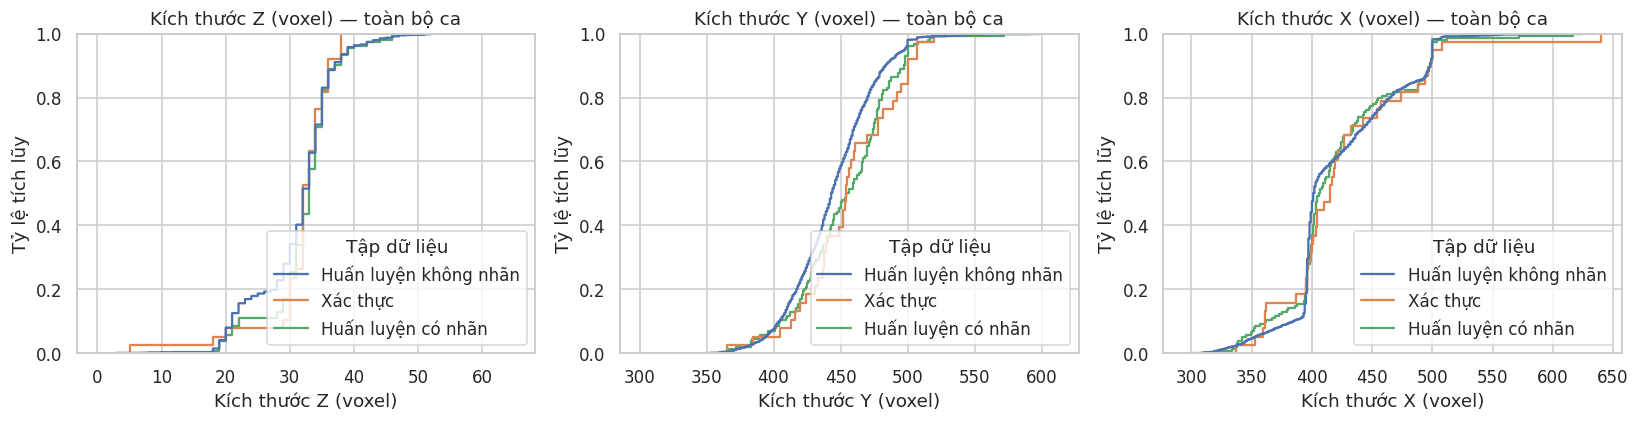

,Kích thước khối ảnh,Phạm vi vật lý (mm),Ca cần đệm (%),Tỷ phần đệm trung bình trên thể tích đã đệm,Số voxel mỗi khối
0,32x160x160,"(160, 80.0, 80.0)",39.539171,0.080271,819200
1,32x192x192,"(160, 96.0, 96.0)",39.539171,0.080271,1179648
2,32x224x224,"(160, 112.0, 112.0)",39.539171,0.080271,1605632
3,48x160x160,"(240, 80.0, 80.0)",99.493088,0.349568,1228800


Các tỷ lệ mô tả đệm trên toàn thể tích, chưa đo VRAM hoặc phần đệm trong từng khối ảnh.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, feature in zip(axes, ['shape_z','shape_y','shape_x']):
    sns.ecdfplot(data=df, x=feature, hue='split', ax=ax)
    ax.set_title(feature + ' — toàn bộ ca')
plt.tight_layout(); plt.show()
# Đo mức đệm; không suy ra Z tối ưu chỉ từ trung vị.
padding_rows = []
for z,y,x in [(32,160,160),(32,192,192),(32,224,224),(48,160,160)]:
    dims = df[['shape_z','shape_y','shape_x']].to_numpy()
    padded = np.maximum(dims, [z,y,x])
    fraction = 1-np.prod(dims,axis=1)/np.prod(padded,axis=1)
    padding_rows.append({'patch': f'{z}x{y}x{x}', 'physical_extent_mm': str((z*5,y*.5,x*.5)),
        'cases_needing_padding_pct': 100*np.mean(np.any(dims < [z,y,x],axis=1)),
        'mean_added_volume_fraction': fraction.mean(), 'patch_voxels': z*y*x})
display(pd.DataFrame(padding_rows))
print('Các tỷ lệ mô tả đệm trên toàn thể tích, chưa đo VRAM hoặc phần đệm trong từng khối ảnh.')

## 3. Cân bằng các loại tổn thương giữa huấn luyện và xác thực

Một ca có thể chứa nhiều lớp tổn thương. Tỷ lệ hiện diện được tính theo số ca; thống kê thể tích chỉ tính các ca có lớp tương ứng. Tỷ lệ tổn thương gộp dùng toàn bộ voxel của thể tích có nhãn sau cắt làm mẫu số. Khác biệt giữa các tập mang tính mô tả, không nên dùng để liên tục điều chỉnh tiền xử lý theo nhãn xác thực.

,Tập dữ liệu,Lớp tổn thương,Số ca,Số ca có lớp,Tỷ lệ hiện diện (%),Tỷ lệ voxel gộp (%),Thể tích trung vị khi có lớp (mL),Thể tích nhỏ nhất khi có lớp (mL),Số ca dưới 1 mL
0,Huấn luyện có nhãn,EDH,154,17,11.038961,0.021205,3.143750,0.36000,3
1,Huấn luyện có nhãn,IPH,154,102,66.233766,0.211784,11.067500,0.00125,15
2,Huấn luyện có nhãn,IVH,154,82,53.246753,0.063009,2.785625,0.04625,27
3,Huấn luyện có nhãn,SAH,154,88,57.142857,0.058159,2.026875,0.07500,27
4,Huấn luyện có nhãn,SDH,154,57,37.012987,0.097679,5.115000,0.51875,7
5,Xác thực,EDH,38,6,15.789474,0.031115,13.919375,4.70250,0
6,Xác thực,IPH,38,23,60.526316,0.088740,5.687500,0.14375,3
7,Xác thực,IVH,38,22,57.894737,0.040687,0.985000,0.05250,11
8,Xác thực,SAH,38,20,52.631579,0.087156,3.183125,0.50875,4
9,Xác thực,SDH,38,13,34.210526,0.104934,21.137500,0.39000,2


Tỷ lệ tổn thương gộp trên dữ liệu có nhãn: 0.4322% voxel của thể tích sau cắt
Độ chính xác voxel khi dự đoán toàn bộ là nền: 99.5678%; chỉ số này không hữu ích để đánh giá phân đoạn.


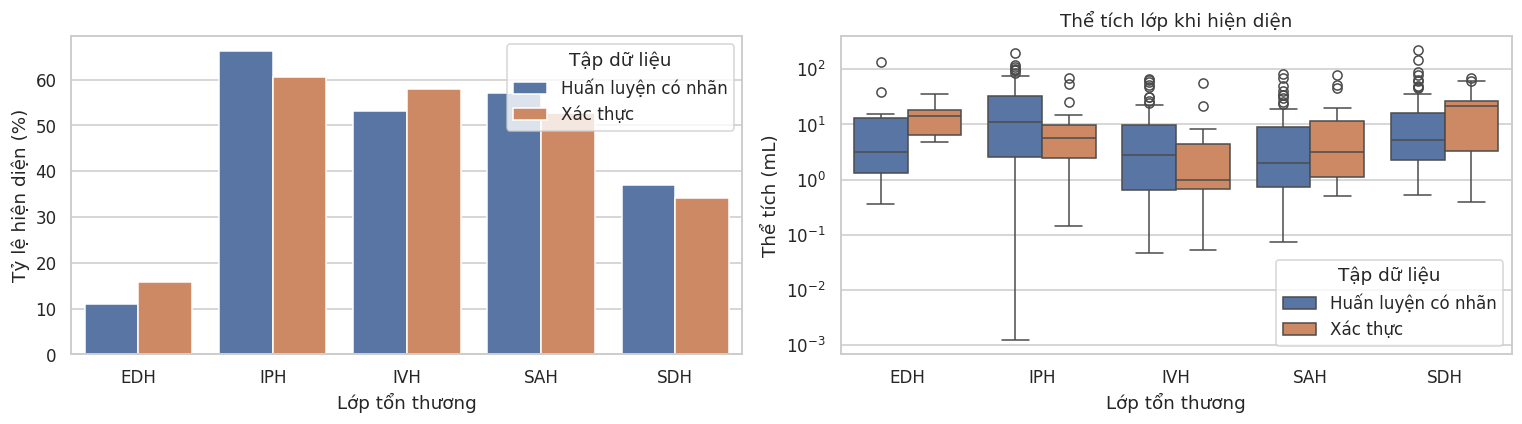

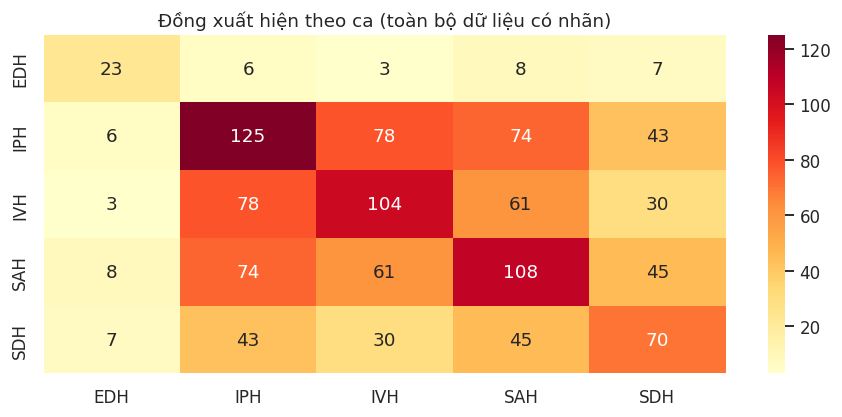

,Tập dữ liệu,Số loại tổn thương,Số ca
0,Huấn luyện có nhãn,0.0,1
1,Huấn luyện có nhãn,1.0,36
2,Huấn luyện có nhãn,2.0,53
3,Huấn luyện có nhãn,3.0,53
4,Huấn luyện có nhãn,4.0,10
5,Huấn luyện có nhãn,5.0,1
6,Xác thực,1.0,13
7,Xác thực,2.0,10
8,Xác thực,3.0,9
9,Xác thực,4.0,6


In [5]:
class_rows = []
for split_name, group in labeled.groupby('split'):
    for c, name in enumerate(CLASS_NAMES, 1):
        present = group[group[f'c{c}_voxels'] > 0]
        class_rows.append({'split': split_name, 'class': name, 'cases': len(group),
            'positive_cases': len(present), 'prevalence_pct': 100*len(present)/len(group),
            'pooled_voxel_share_pct': 100*group[f'c{c}_voxels'].sum()/group.total_voxels.sum(),
            'median_ml_when_present': present[f'c{c}_ml'].median(),
            'min_ml_when_present': present[f'c{c}_ml'].min(),
            'cases_below_1ml': int((present[f'c{c}_ml'] < 1).sum())})
class_table = pd.DataFrame(class_rows)
display(class_table)
class_table.to_csv(OUT/'bhsd_split_class_balance.csv', index=False)
ratio = labeled.lesion_voxels.sum()/labeled.total_voxels.sum()
print(f'Tỷ lệ tổn thương gộp trên dữ liệu có nhãn: {100*ratio:.4f}% voxel của thể tích sau cắt')
print(f'Độ chính xác voxel khi dự đoán toàn bộ là nền: {100*(1-ratio):.4f}%; chỉ số này không hữu ích để đánh giá phân đoạn.')
fig, axes = plt.subplots(1,2, figsize=(14,4))
sns.barplot(data=class_table, x='class', y='prevalence_pct', hue='split', ax=axes[0])
volumes = labeled.melt(id_vars=['case_id','split'], value_vars=[f'c{c}_ml' for c in range(1,6)], value_name='ml', var_name='class')
sns.boxplot(data=volumes[volumes.ml > 0], x='class', y='ml', hue='split', ax=axes[1])
axes[1].set_yscale('log'); axes[1].set_title('Thể tích lớp khi hiện diện')
plt.tight_layout(); plt.show()
presence = labeled[[f'c{c}_voxels' for c in range(1,6)]].gt(0).astype(int)
cooccurrence = presence.T @ presence
cooccurrence.index = cooccurrence.columns = CLASS_NAMES
sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='YlOrRd'); plt.title('Đồng xuất hiện theo ca (toàn bộ dữ liệu có nhãn)'); plt.show()
display(labeled.groupby(['split','num_lesion_types']).size().rename('cases').reset_index())

## 4. Biến đổi cường độ và so sánh các nhóm dữ liệu

Giới hạn cửa sổ HU làm bão hòa giá trị ngoài khoảng, không loại bỏ xương hay không khí. Chuẩn hóa toàn cục không bảo đảm mỗi ảnh có trung bình 0 và phương sai 1; `image > image.min()` không phải mặt nạ não đã được kiểm chứng. Các hằng số dưới đây lấy từ thuộc tính H5, kèm số ca sử dụng từng tổ hợp tham số.

Kiểm định KS so sánh **tập huấn luyện có nhãn** với toàn bộ tập không nhãn, loại tập xác thực khỏi phép so sánh. Báo cáo thống kê D, giá trị p gốc và p hiệu chỉnh Holm trên các đặc trưng được kiểm định. Giá trị p lớn không chứng minh tính tương đương; các đặc trưng này chưa đủ để loại trừ khác biệt về máy chụp, quy trình chụp, bệnh lý hoặc cách chọn mẫu. Đặc trưng cường độ được đo sau tiền xử lý.

,Ngưỡng HU dưới,Ngưỡng HU trên,Trung bình chuẩn hóa,Độ lệch chuẩn dùng chuẩn hóa,Số ca
0,11.0,88.0,47.6804,18.4999,2170


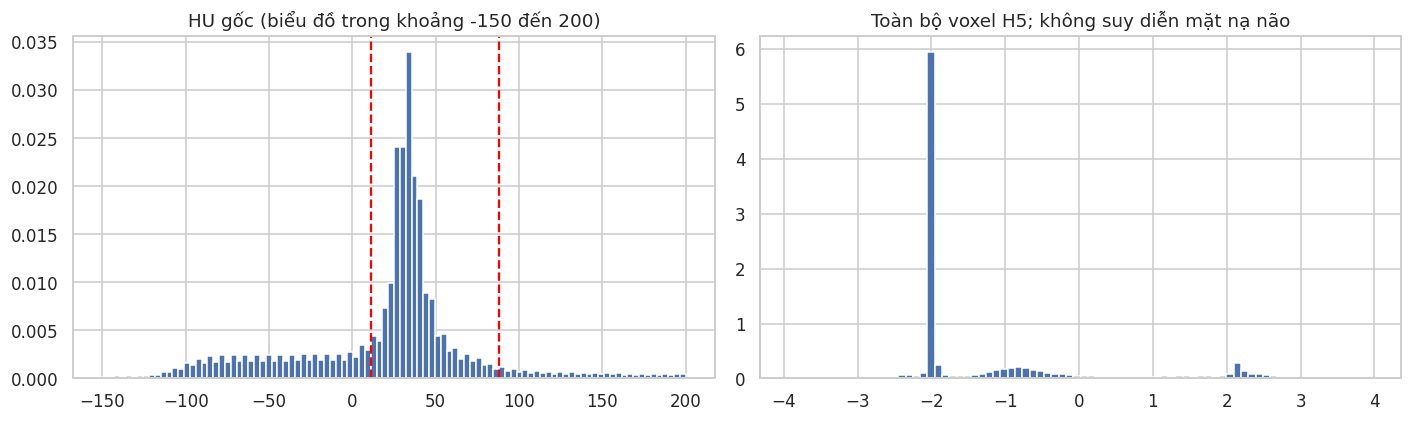

Phép biến đổi đã ghi: (clip(HU, [11.0, 88.0]) - 47.6804) / 18.4999
Giới hạn lý thuyết sau cắt ngưỡng và chuẩn hóa: [-1.9827350418110368, 2.1794496186465873]


,Đặc trưng,Số ca huấn luyện có nhãn,Số ca không nhãn,Thống kê D của KS,Giá trị p,p hiệu chỉnh Holm,"Phát hiện khác biệt ở mức 0,05"
0,Kích thước Z (voxel),154,1978,0.111755,0.051866,0.155599,Không
1,Kích thước Y (voxel),154,1978,0.188935,0.000061,0.000489,Có
2,Kích thước X (voxel),154,1978,0.105603,0.076436,0.155599,Không
3,Khoảng cách lấy mẫu gốc Z (mm),154,1978,0.158792,0.001291,0.009037,Có
4,Khoảng cách lấy mẫu gốc Y (mm),154,1978,0.134223,0.010440,0.052202,Không
5,Khoảng cách lấy mẫu gốc X (mm),154,1978,0.134223,0.010440,0.052202,Không
6,Cường độ trung bình,154,1977,0.065973,0.539231,0.539231,Không
7,Độ lệch chuẩn cường độ,154,1977,0.154964,0.001831,0.010984,Có


Đặc trưng phát hiện khác biệt: ['Kích thước Y (voxel)', 'Khoảng cách lấy mẫu gốc Z (mm)', 'Độ lệch chuẩn cường độ']
Chưa thể kết luận không có dịch chuyển phân phối hoặc máy chụp tương đương.


In [6]:
display(df.groupby(['clip_min','clip_max','norm_mean','norm_std']).size().rename('cases').reset_index())
case_id = train.sort_values('case_id').iloc[0].case_id
raw_image = nib.load(RAW_DIR/'images'/f'{case_id}.nii.gz')
raw_hu = np.asarray(raw_image.dataobj, dtype=np.float32)
with h5py.File(DATASET_DIR/'data'/f'{case_id}.h5') as f:
    image = f['image'][:]
    attrs = dict(f.attrs)
clip, norm = parse(attrs['clip_range']), parse(attrs['norm_params'])
fig, axes = plt.subplots(1,2, figsize=(13,4))
axes[0].hist(raw_hu.ravel(), bins=100, range=(-150,200), density=True)
for value in clip: axes[0].axvline(value, color='red', linestyle='--')
axes[0].set_title('HU gốc (biểu đồ trong khoảng -150 đến 200)')
axes[1].hist(image.ravel(), bins=80, density=True)
axes[1].set_title('Toàn bộ voxel H5; không suy diễn mặt nạ não')
plt.tight_layout(); plt.show()
print('Phép biến đổi đã ghi:', f'(clip(HU, {clip}) - {norm["mean"]}) / {norm["std"]}')
print('Giới hạn lý thuyết sau cắt ngưỡng và chuẩn hóa:', [(v-norm['mean'])/norm['std'] for v in clip])
features = ['shape_z','shape_y','shape_x','orig_spacing_z','orig_spacing_y','orig_spacing_x','img_mean','img_std']
ks_rows = []
for feature in features:
    a,b = train[feature].dropna(), unlabeled[feature].dropna()
    result = stats.ks_2samp(a,b)
    ks_rows.append({'feature': feature, 'n_labeled_train': len(a), 'n_unlabeled': len(b),
                    'KS_D': result.statistic, 'p': result.pvalue})
ks = pd.DataFrame(ks_rows)
order = np.argsort(ks.p.to_numpy())
adjusted = np.minimum(1, np.maximum.accumulate(ks.p.to_numpy()[order]*(len(ks)-np.arange(len(ks)))))
ks.loc[order,'p_holm'] = adjusted
ks['difference_detected_at_0.05'] = ks.p_holm < .05
display(ks)
ks.to_csv(OUT/'bhsd_cohort_comparison.csv', index=False)
print('Đặc trưng phát hiện khác biệt:', [vi(f) for f in ks.loc[ks['difference_detected_at_0.05'],'feature']])
print('Chưa thể kết luận không có dịch chuyển phân phối hoặc máy chụp tương đương.')

## 5. Kiểm tra định lượng bảo toàn nhãn: GT gốc → cắt → H5

NIfTI gốc được đọc theo thứ tự X,Y,Z và chuyển sang Z,Y,X của H5. Ảnh gốc và GT phải có cùng ma trận affine, cùng kích thước, đồng thời khớp với kích thước và khoảng cách lấy mẫu gốc ghi trong H5. Đây là kiểm tra siêu dữ liệu, chưa phải bằng chứng độc lập về độ chính xác của đăng ký ảnh.

Số voxel bị cắt mất được đếm trực tiếp trên GT gốc trước khi lấy mẫu lại. Thay đổi thể tích dùng tích các khoảng cách lấy mẫu đã ghi; `raw_affine_ml` dùng riêng định thức ma trận affine để xem xét hình học nghiêng/xiên. Hai quy ước này có thể cho kết quả khác nhau.

`diagnostic_forward_dice` dùng nội suy láng giềng gần nhất của `scipy.ndimage.zoom` với quy ước căn theo điểm đầu/cuối mặc định trên nhãn gốc đã cắt. H5 không ghi thư viện lấy mẫu lại, quy ước tọa độ và phép nội suy nhãn ban đầu, nên Dice này chỉ là **ước lượng phục vụ kiểm tra**, không xác nhận tiền xử lý đúng. Lớp biến mất, thay đổi thể tích lớn và tổn thương chạm biên là các dấu hiệu cần rà soát.

In [7]:
print('Số cặp ca–lớp gốc/H5 đã kiểm tra:', len(retention))
positive_raw = retention[retention.raw_voxels > 0]
display(positive_raw.groupby('class_name').agg(
    positive_raw_cases=('case_id','size'), cropped_out_voxels=('cropped_out_voxels','sum'),
    disappeared_cases=('disappeared','sum'), median_volume_change_pct=('volume_change_pct','median'),
    min_diagnostic_dice=('diagnostic_forward_dice','min'), median_diagnostic_dice=('diagnostic_forward_dice','median')))
flags = retention[(retention.cropped_out_voxels > 0) | retention.disappeared | retention.appeared |
                  (retention.volume_change_pct.abs() > 20)]
display(flags.sort_values('volume_change_pct', key=lambda s: s.abs(), ascending=False))
flags.to_csv(OUT/'bhsd_preprocessing_review_cases.csv', index=False)
print('Ngoại lệ hình học nguồn cần rà soát:')
display(outliers[['case_id','orig_shape_z','orig_spacing_z','shape_z','lesion_ml']])
print('Cần rà soát siêu dữ liệu thu nhận và nguồn gốc tiền xử lý; không tự động sửa ảnh/nhãn nguồn.')

Số cặp ca–lớp gốc/H5 đã kiểm tra: 940


,Số ca có lớp trong GT gốc,Số voxel bị cắt mất,Số ca mất lớp,Thay đổi thể tích trung vị (%),Dice kiểm tra nhỏ nhất,Dice kiểm tra trung vị
Lớp tổn thương,,,,,,
EDH,23,0,0,-1.429556,1.0,1.0
IPH,124,0,2,-0.354110,1.0,1.0
IVH,102,4,0,0.127019,1.0,1.0
SAH,106,0,1,-0.054554,1.0,1.0
SDH,69,29,0,0.107953,1.0,1.0


,Mã ca,Tập dữ liệu,Mã lớp,Lớp tổn thương,Số voxel GT gốc,Số voxel sau cắt,Số voxel H5,Số voxel bị cắt mất,Lớp biến mất,Lớp xuất hiện mới,Thể tích gốc theo spacing (mL),Thể tích H5 (mL),Thể tích gốc theo affine (mL),Thay đổi thể tích (%),Dice kiểm tra lấy mẫu thuận
296,ID_56faaf6f_ID_dd8f688dff,Xác thực,2,IPH,3991,3991,0,0,Có,Không,0.475764,0.00000,0.475764,-100.000000,NaN
386,ID_6caf8d60_ID_3634a47122,Huấn luyện có nhãn,2,IPH,88,88,0,0,Có,Không,0.052452,0.00000,0.052452,-100.000000,NaN
568,ID_9ba3be10_ID_1c4e9f3c40,Xác thực,4,SAH,48,48,0,0,Có,Không,0.028967,0.00000,0.028967,-100.000000,NaN
208,ID_3bda60be_ID_067209cc9a,Huấn luyện có nhãn,4,SAH,1378,1378,103,0,Không,Không,0.856505,0.12875,0.856505,-84.967972,1.0
562,ID_9a8ad2df_ID_0ec627c99a,Huấn luyện có nhãn,3,IVH,663,663,544,0,Không,Không,0.413198,0.68000,0.413198,64.569896,1.0
192,ID_39702b69_ID_167ab8c629,Huấn luyện có nhãn,3,IVH,430,430,726,0,Không,Không,0.561107,0.90750,0.561107,61.733940,1.0
299,ID_56faaf6f_ID_dd8f688dff,Xác thực,5,SDH,8516,8516,312,0,Không,Không,1.015185,0.39000,1.015185,-61.583369,1.0
707,ID_b972b07f_ID_b5ace7f563,Huấn luyện có nhãn,3,IVH,1808,1808,2808,0,Không,Không,2.247980,3.51000,2.247980,56.140186,1.0
807,ID_d9675573_ID_02237f7694,Huấn luyện có nhãn,3,IVH,1313,1313,314,0,Không,Không,0.804834,0.39250,0.804834,-51.232199,1.0
82,ID_16ed917a_ID_145f184354,Huấn luyện có nhãn,3,IVH,205,205,300,0,Không,Không,0.252981,0.37500,0.252981,48.232495,1.0


Ngoại lệ hình học nguồn cần rà soát:


,Mã ca,Kích thước gốc Z (voxel),Khoảng cách lấy mẫu gốc Z (mm),Kích thước Z (voxel),Thể tích tổn thương (mL)
757,ID_56faaf6f_ID_dd8f688dff,48,0.5,5,4.27


Cần rà soát siêu dữ liệu thu nhận và nguồn gốc tiền xử lý; không tự động sửa ảnh/nhãn nguồn.


### Kiểm tra đa mặt phẳng trên cùng lưới gốc

H5 được lấy mẫu ngược xấp xỉ về kích thước sau cắt đã ghi, đặt lại theo độ lệch hộp bao, rồi so sánh tại cùng chỉ số voxel trên lưới gốc. Chỉ số voxel được ánh xạ sang tọa độ vật lý qua affine của ảnh gốc; ảnh và nhãn phải dùng cùng affine. Các hình thể hiện mặt phẳng thu nhận gốc, có thể nghiêng, chứ chưa phải tái tạo theo mặt phẳng giải phẫu chuẩn. Tỷ lệ hiển thị vật lý dùng độ dài các cột affine.

Cách này thay cho phép so sánh trước đây dùng tỷ lệ chỉ số lát cắt và các điểm giữa không tương ứng. Phép khôi phục giả định căn theo điểm đầu/cuối; chưa thể xác nhận đường biên khớp tuyệt đối.

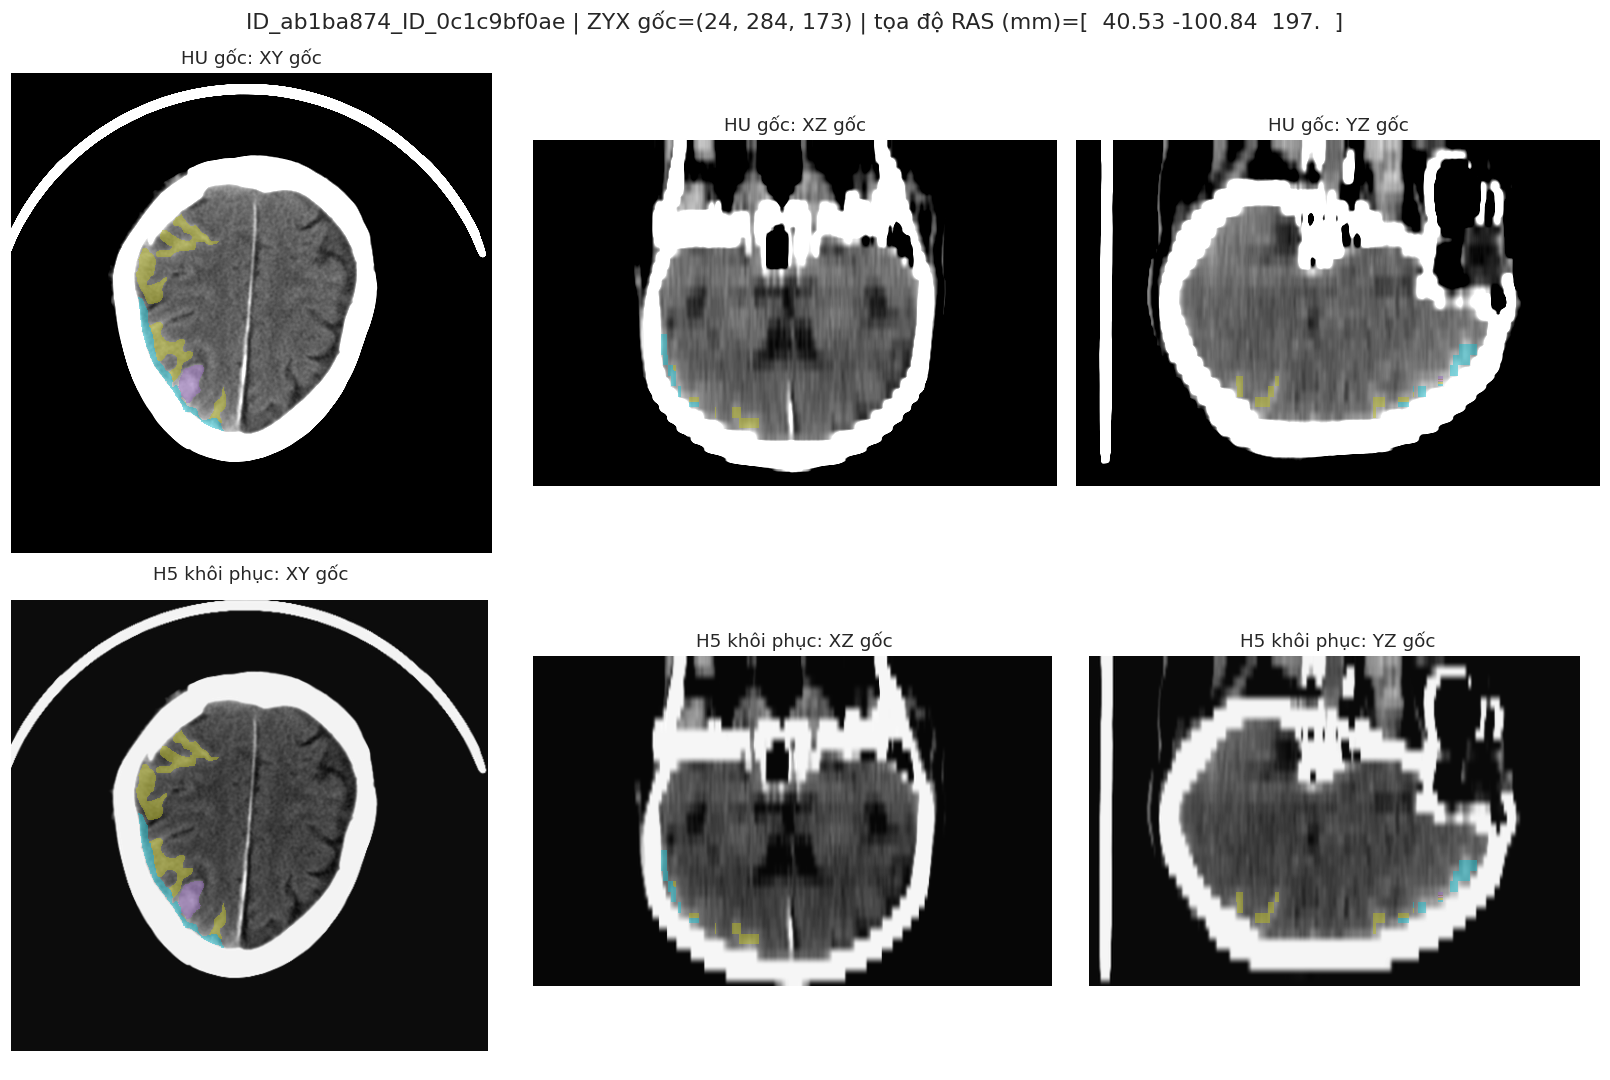

In [8]:
# Chọn ca huấn luyện có nhiều lớp để minh họa.
selected = train.sort_values(['num_lesion_types','case_id'], ascending=[False,True]).iloc[0].case_id
raw_img_n = nib.load(RAW_DIR/'images'/f'{selected}.nii.gz')
raw_gt_n = nib.load(RAW_DIR/'ground truths'/f'{selected}.nii.gz')
assert raw_img_n.shape == raw_gt_n.shape and np.allclose(raw_img_n.affine, raw_gt_n.affine)
raw_img = np.asarray(raw_img_n.dataobj, dtype=np.float32).transpose(2,1,0)
raw_gt = np.asarray(raw_gt_n.dataobj).transpose(2,1,0)
with h5py.File(DATASET_DIR/'data'/f'{selected}.h5') as f:
    h5_img, h5_gt = f['image'][:], f['label'][:]
    attrs = dict(f.attrs)
bbox, cropped = np.array(parse(attrs['bbox_used'])), np.array(parse(attrs['cropped_shape']))
assert tuple(parse(attrs['orig_shape'])) == raw_img.shape
inverse_img = ndimage.zoom(h5_img, cropped/np.array(h5_img.shape), order=1, prefilter=False)
inverse_gt = ndimage.zoom(h5_gt, cropped/np.array(h5_gt.shape), order=0, prefilter=False)
restored_img = np.full(raw_img.shape, np.nan, dtype=np.float32)
restored_gt = np.zeros_like(raw_gt)
region = tuple(slice(a,b) for a,b in bbox)
restored_img[region], restored_gt[region] = inverse_img, inverse_gt
z = int(np.argmax((raw_gt > 0).sum(axis=(1,2))))
coords = np.argwhere(raw_gt[z] > 0)
y,x = np.median(coords, axis=0).astype(int) if len(coords) else np.array(raw_img.shape[1:])//2
world = nib.affines.apply_affine(raw_img_n.affine, [x,y,z])
spacing_zyx = np.linalg.norm(raw_img_n.affine[:3,:3],axis=0)[::-1]
planes = [(lambda a: a[z], spacing_zyx[1]/spacing_zyx[2], 'XY gốc'),
          (lambda a: a[:,y,:], spacing_zyx[0]/spacing_zyx[2], 'XZ gốc'),
          (lambda a: a[:,:,x], spacing_zyx[0]/spacing_zyx[1], 'YZ gốc')]
fig, axes = plt.subplots(2,3,figsize=(15,10))
for j,(plane,aspect,title) in enumerate(planes):
    for i,(img,lbl,label) in enumerate([(raw_img,raw_gt,'HU gốc'),(restored_img,restored_gt,'H5 khôi phục')]):
        axes[i,j].imshow(plane(img), cmap='gray', aspect=aspect,
                         **({'vmin':0,'vmax':80} if i == 0 else {}))
        axes[i,j].imshow(np.ma.masked_where(plane(lbl)==0,plane(lbl)), cmap='tab10',vmin=0,vmax=5,alpha=.5,aspect=aspect)
        axes[i,j].set_title(f'{label}: {title}'); axes[i,j].axis('off')
plt.suptitle(f'{selected} | ZYX gốc={z,y,x} | tọa độ RAS (mm)={np.round(world,2)}')
plt.tight_layout(); plt.show()

## 6. Lấy mẫu khối ảnh trên toàn bộ ca huấn luyện có nhãn

Sử dụng đúng `data.transforms3d.RandomCrop` của mã huấn luyện, gồm đệm số 0 đối xứng, dịch ngẫu nhiên tâm quanh vùng tổn thương và xử lý GT rỗng. Ảnh được thay bằng nhãn vì việc lấy mẫu chỉ phụ thuộc hình học và GT. Hạt giống ngẫu nhiên được cố định cho từng ca/cấu hình; kết quả là ước lượng Monte Carlo, không bảo đảm mô hình hội tụ.

So sánh ba kích thước XY và xác suất chọn tâm theo tổn thương 0; 0,33; 0,5. Báo cáo tỷ lệ gặp tổn thương trung bình với trọng số bằng nhau giữa các ca, tỷ lệ theo lớp có điều kiện, tỷ phần tổn thương trong khối ảnh và phân bố theo tổng thể tích tổn thương. Trung bình kèm khoảng bootstrap 95% theo ca (1.000 lần lấy mẫu lại; phụ thuộc mô phỏng hữu hạn này). Các ca không có một lớp được loại khỏi mẫu số khi tính tỷ lệ gặp lớp đó.

Đây là xác suất trên **khối ảnh**, không phải trên lô huấn luyện. Dữ liệu không nhãn không thể lấy mẫu dựa trên GT; lấy mẫu dựa trên nhãn giả cần một thí nghiệm riêng.

Số ca  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương          
32x160x160          0.00                                 154   
                    0.33                                 154   
                    0.50                                 154   
32x192x192          0.00                                 154   
                    0.33                                 154   
                    0.50                                 154   
32x224x224          0.00                                 154   
                    0.33                                 154   
                    0.50                                 154   

                                                       Tỷ lệ gặp tổn thương trung bình theo ca  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương                                            
32x160x160          0.00                                                              0.689448   
                    0.33                                                              0.786851   
                    0.50                                                              0.842208   
32x192x192          0.00                                                              0.805032   
                    0.33                                                              0.856818   
                    0.50                                                              0.893831   
32x224x224          0.00                                                              0.877110   
                    0.33                                                              0.914610   
                    0.50                                                              0.939773   

                                                       Tỷ lệ gặp tổn thương trung vị theo ca  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương                                          
32x160x160          0.00                                                               0.725   
                    0.33                                                               0.800   
                    0.50                                                               0.875   
32x192x192          0.00                                                               0.900   
                    0.33                                                               0.925   
                    0.50                                                               0.950   
32x224x224          0.00                                                               1.000   
                    0.33                                                               1.000   
                    0.50                                                               1.000   

                                                       Tỷ lệ gặp tổn thương nhỏ nhất theo ca  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương                                          
32x160x160          0.00                                                                 0.0   
                    0.33                                                                 0.0   
                    0.50                                                                 0.0   
32x192x192          0.00                                                                 0.0   
                    0.33                                                                 0.0   
                    0.50                                                                 0.0   
32x224x224          0.00                                                                 0.0   
                    0.33                                                                 0.0   
                    0.50                                                                 0.0   

                                                       Tỷ phần tổn thương trung bình trong khối  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương     

,Kích thước khối ảnh,Xác suất chọn tâm theo tổn thương,Lớp tổn thương,Số ca có lớp,Tỷ lệ gặp lớp trung bình khi có lớp
0,32x160x160,0.00,EDH,17,0.405882
1,32x160x160,0.00,IPH,102,0.528431
2,32x160x160,0.00,IVH,82,0.560061
3,32x160x160,0.00,SAH,88,0.597159
4,32x160x160,0.00,SDH,57,0.525877
5,32x160x160,0.33,EDH,17,0.557353
6,32x160x160,0.33,IPH,102,0.658333
7,32x160x160,0.33,IVH,82,0.626524
8,32x160x160,0.33,SAH,88,0.691477
9,32x160x160,0.33,SDH,57,0.629386


Số lượng  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương Nhóm thể tích tổn thương             
32x160x160          0.00                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
                    0.33                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
                    0.50                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
32x192x192          0.00                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
                    0.33                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
                    0.50                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
32x224x224          0.00                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
                    0.33                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   
                    0.50                              Không có tổn thương              1   
                                                      (0,1] ml                        15   
                                                      (1,10] ml                       41   
                                                      >10 ml                          97   

                                                                                Trung bình  \
Kích thước khối ảnh Xác suất chọn tâm theo tổn thương Nhóm thể tích tổn thương               
32x160x160          0.00                              Không có tổn thương         0.000000   
                                                      (0,1] ml                    0.380000   
                                                      (1,10] ml                   0.542683   
                                                      >10 ml                      0.806443   
                   

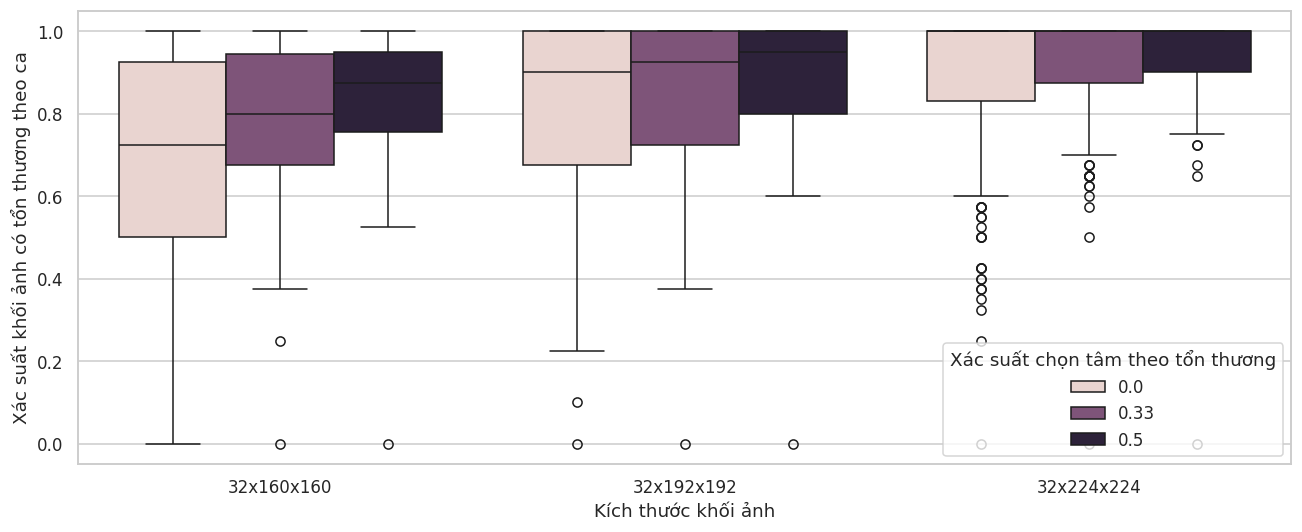

Chọn xác suất lấy mẫu qua thí nghiệm huấn luyện; chưa có cơ sở bắt buộc dùng ngưỡng 0,5.


In [9]:
# Kiểm tra đệm theo nguồn, mã lấy mẫu/xử lý và cấu hình hạt giống/số lần thử.
import hashlib
sampling_path = OUT/'bhsd_patch_sampling.csv'
sampling_manifest = OUT/'bhsd_patch_sampling_manifest.json'
sampling_key = {'trials': TRIALS, 'seed': SEED,
    'patches': [[32,160,160],[32,192,192],[32,224,224]], 'foreground_probabilities':[0.,.33,.5],
    'sources': fingerprint([DATASET_DIR/'data'/f'{c}.h5' for c in sorted(train.case_id)]),
    'sampler_sha256': hashlib.sha256((ROOT/'data/transforms3d.py').read_bytes()).hexdigest()}
if sampling_path.exists() and sampling_manifest.exists() and json.loads(sampling_manifest.read_text()) == sampling_key:
    sampling = pd.read_csv(sampling_path)
else:
    rows = []
    for i, case_id in enumerate(sorted(train.case_id),1):
        rows.extend(sample_case(case_id, DATASET_DIR, trials=TRIALS, seed=SEED))
        if i % 25 == 0: print(f'Đã lấy mẫu {i}/{len(train)} ca huấn luyện', flush=True)
    sampling = pd.DataFrame(rows)
    sampling.to_csv(sampling_path,index=False)
    sampling_manifest.write_text(json.dumps(sampling_key,indent=2))
assert sampling.case_id.nunique() == len(train)
summary = sampling.groupby(['patch','foreground_prob']).agg(
    cases=('case_id','size'), mean_case_hit_rate=('any_hit_rate','mean'),
    median_case_hit_rate=('any_hit_rate','median'), min_case_hit_rate=('any_hit_rate','min'),
    mean_patch_fg_fraction=('fg_fraction','mean'))
# Bootstrap theo ca độc lập; các khối ảnh trong cùng ca có thể tương quan.
bootstrap_rng = np.random.default_rng(SEED)
for key, group in sampling.groupby(['patch','foreground_prob']):
    rates = group.any_hit_rate.to_numpy()
    means = bootstrap_rng.choice(rates, size=(1000,len(rates)), replace=True).mean(axis=1)
    summary.loc[key,'case_bootstrap_low_95'] = np.quantile(means,.025)
    summary.loc[key,'case_bootstrap_high_95'] = np.quantile(means,.975)
display(summary)
summary.to_csv(OUT/'bhsd_patch_sampling_summary.csv')
class_sampling = []
for (patch,prob), group in sampling.groupby(['patch','foreground_prob']):
    for c,name in enumerate(CLASS_NAMES,1):
        present = group[group[f'c{c}_present']]
        class_sampling.append({'patch':patch,'foreground_prob':prob,'class':name,
            'positive_cases':len(present),'mean_conditional_hit_rate':present[f'c{c}_hit_rate'].mean()})
class_sampling = pd.DataFrame(class_sampling)
display(class_sampling)
class_sampling.to_csv(OUT/'bhsd_patch_sampling_by_class.csv',index=False)
sampling['lesion_ml'] = sampling.case_id.map(train.set_index('case_id').lesion_ml)
sampling['burden'] = pd.cut(sampling.lesion_ml, [-np.inf,0,1,10,np.inf], labels=['Không có tổn thương','(0,1] ml','(1,10] ml','>10 ml'])
display(sampling.groupby(['patch','foreground_prob','burden'],observed=True).any_hit_rate.agg(['count','mean','min']))
fig, ax = plt.subplots(figsize=(12,5))
sns.boxplot(data=sampling,x='patch',y='any_hit_rate',hue='foreground_prob',ax=ax)
ax.set_ylabel('Xác suất khối ảnh có tổn thương theo ca'); plt.tight_layout(); plt.show()
print('Chọn xác suất lấy mẫu qua thí nghiệm huấn luyện; chưa có cơ sở bắt buộc dùng ngưỡng 0,5.')

## 7. Hình thái tổn thương: đơn vị và phạm vi phân tích

Mỗi dòng biểu diễn **hợp vùng của một cặp ca–lớp**, bao gồm cả các thành phần rời nhau, không phải một tổn thương riêng lẻ. `components_26` đếm số thành phần liên thông 26 lân cận; chưa phân tích hình dạng từng thành phần. Diện tích bề mặt được tính bằng marching cubes trên mặt nạ đã đệm theo đơn vị mm vật lý; thể tích bằng số voxel nhân tích khoảng cách lấy mẫu. SAVR là A/V theo **cm⁻¹**: `surface_area_cm2 / vol_ml`. Độ cầu không có đơn vị.

Giữ lại mọi mặt nạ dương tính, kể cả chỉ có một voxel. Chỉ số PCA không xác định trên mặt nạ suy biến được ghi NaN. Các chỉ số tự định nghĩa là `elongation = 1-sqrt(lambda2/lambda1)` và `flatness = 1-sqrt(lambda3/lambda2)`, với lambda là trị riêng của ma trận hiệp phương sai tọa độ vật lý; tên gọi không hàm ý đây là định nghĩa radiomics chuẩn.

Lấy mẫu lại bất đẳng hướng, rời rạc hóa voxel, mặt nạ nhỏ và hợp các vùng rời nhau ảnh hưởng đến ước lượng. Đặc biệt, thể tích đếm theo voxel kết hợp bề mặt tam giác hóa có thể cho độ cầu > 1 ở mặt nạ rất nhỏ. Các sai lệch số này được đánh dấu, không diễn giải như hình dạng vật lý thực. Thống kê hình thái mang tính mô tả, chưa phải chẩn đoán hay bằng chứng bắt buộc dùng một hàm mất mát/kiến trúc.

Sai lệch rời rạc hóa: độ cầu > 1 (giữ nguyên giá trị):


,Mã ca,Lớp tổn thương,Số voxel,Độ cầu
364,ID_d8e67d7d_ID_c182bd8176,IPH,1,1.583262


Số hợp vùng ca–lớp  \
Tập dữ liệu        Lớp tổn thương                       
Huấn luyện có nhãn EDH                             17   
                   IPH                            102   
                   IVH                             82   
                   SAH                             88   
                   SDH                             57   
Xác thực           EDH                              6   
                   IPH                             23   
                   IVH                             22   
                   SAH                             20   
                   SDH                             13   

                                   Số mặt nạ có PCA xác định  Độ cầu trung vị  \
Tập dữ liệu        Lớp tổn thương                                               
Huấn luyện có nhãn EDH                                    17         0.510552   
                   IPH                                   101         0.556204   
                   IVH                                    82         0.456169   
                   SAH                                    88         0.353301   
                   SDH                                    57         0.320334   
Xác thực           EDH                                     6         0.428659   
                   IPH                                    23         0.544288   
                   IVH                                    22         0.490667   
                   SAH                                    20         0.296990   
                   SDH                                    13         0.264865   

                                   SAVR trung vị (cm⁻¹)  Độ phẳng trung vị  \
Tập dữ liệu        Lớp tổn thương                                            
Huấn luyện có nhãn EDH                         6.664616           0.588424   
                   IPH                         4.167255           0.293803   
                   IVH                         7.948414           0.431333   
                   SAH                        10.700986           0.456530   
                   SDH                         8.679545           0.615612   
Xác thực           EDH                         4.421592           0.646415   
                   IPH                         5.185632           0.300482   
                   IVH                         8.488354           0.503032   
                   SAH                        10.058550           0.390889   
                   SDH                         7.373859           0.646112   

                                   Số thành phần trung vị  
Tập dữ liệu        Lớp tổn thương                          
Huấn luyện có nhãn EDH                                1.0  
                   IPH                                1.0  
                   IVH                                3.0  
                   SAH                                5.5  
                   SDH                                3.0  
Xác thực           EDH                                1.5  
                   IPH                                2.0  
                   IVH                                2.0  
                   SAH                                8.0  
                   SDH                                3.0

Mặt nạ rất nhỏ (được giữ lại đầy đủ):


,Mã ca,Mã lớp,Lớp tổn thương,Số voxel,Thể tích (mL),Diện tích bề mặt (cm²),Độ cầu,SAVR,Đơn vị SAVR,Độ kéo dài,Độ phẳng,Tỷ phần lấp đầy hộp bao,Số thành phần liên thông 26 lân cận,Số mặt nạ có PCA xác định,Tập dữ liệu
364,ID_d8e67d7d_ID_c182bd8176,2,IPH,1,0.00125,0.035444,1.583262,28.354894,cm^-1,NaN,NaN,1.0,1,Không,Huấn luyện có nhãn


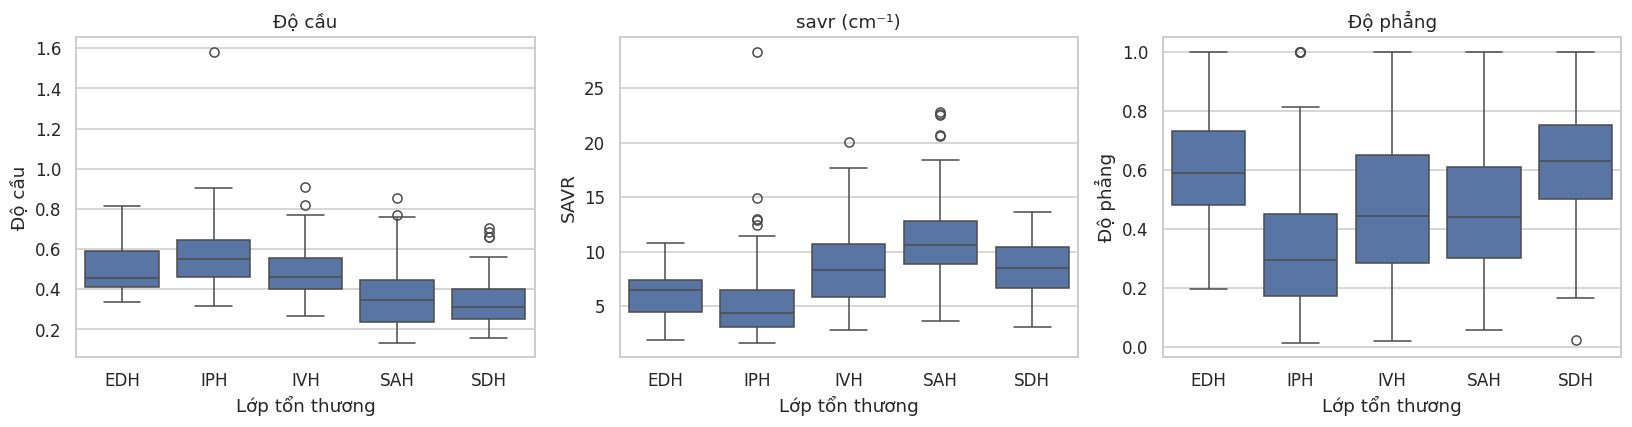

In [10]:
expected_rows = int(sum((labeled[f'c{c}_voxels'] > 0).sum() for c in range(1,6)))
assert len(shape) == expected_rows and not shape.duplicated(['case_id','class_id']).any()
assert np.allclose(shape.savr,shape.surface_area_cm2/shape.vol_ml)
assert np.isfinite(shape.sphericity).all() and np.isfinite(shape.savr).all()
print('Sai lệch rời rạc hóa: độ cầu > 1 (giữ nguyên giá trị):')
display(shape[shape.sphericity > 1][['case_id','class_name','voxels','sphericity']])
shape['split'] = shape.case_id.map(labeled.set_index('case_id').split)
display(shape.groupby(['split','class_name']).agg(
    case_class_unions=('case_id','size'), pca_defined=('pca_defined','sum'),
    median_sphericity=('sphericity','median'), median_savr_cm_inverse=('savr','median'),
    median_flatness=('flatness','median'), median_components=('components_26','median')))
print('Mặt nạ rất nhỏ (được giữ lại đầy đủ):')
display(shape[shape.voxels < 10])
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['sphericity','savr','flatness']):
    sns.boxplot(data=shape,x='class_name',y=metric,order=CLASS_NAMES,ax=ax)
    ax.set_title(metric + (' (cm⁻¹)' if metric == 'savr' else ''))
plt.tight_layout(); plt.show()

### Minh họa từng lớp từ tập huấn luyện

Với mỗi lớp, chọn ca huấn luyện dương tính có thể tích lớp gần trung vị nhất. Hiển thị lát cắt ngang có diện tích lớp lớn nhất. Quy tắc chọn dựa trên thể tích và có thể tái lập; các ví dụ không được khẳng định là hình thái bệnh lý điển hình.

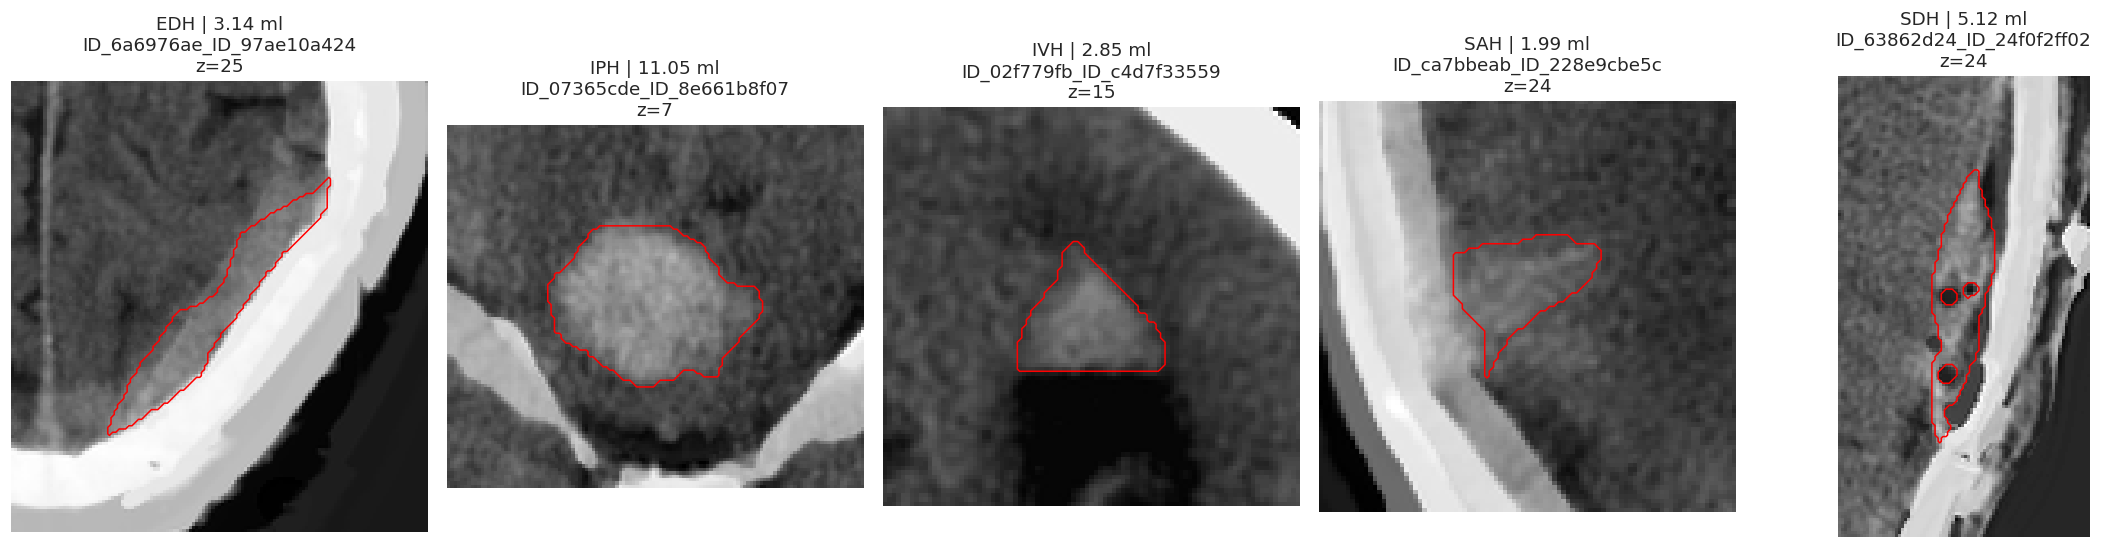

In [11]:
fig, axes = plt.subplots(1,5,figsize=(20,5))
for c,(name,ax) in enumerate(zip(CLASS_NAMES,axes),1):
    positives = train[train[f'c{c}_ml'] > 0].copy()
    positives['distance'] = (positives[f'c{c}_ml']-positives[f'c{c}_ml'].median()).abs()
    chosen = positives.sort_values(['distance','case_id']).iloc[0]
    with h5py.File(DATASET_DIR/'data'/f'{chosen.case_id}.h5') as f:
        image, label = f['image'][:], f['label'][:]
    z = int(np.argmax((label == c).sum(axis=(1,2))))
    points = np.argwhere(label[z] == c)
    lo = np.maximum(0,points.min(axis=0)-30)
    hi = np.minimum(image.shape[1:],points.max(axis=0)+31)
    plane = image[z,lo[0]:hi[0],lo[1]:hi[1]]
    mask = label[z,lo[0]:hi[0],lo[1]:hi[1]] == c
    ax.imshow(plane,cmap='gray',aspect=.5/.5)
    ax.contour(mask,levels=[.5],colors=['red'],linewidths=1)
    ax.set_title(f'{name} | {chosen[f"c{c}_ml"]:.2f} ml\n{chosen.case_id}\nz={z}',fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 8. Từ bằng chứng đến thí nghiệm và các vấn đề cần rà soát

| Bằng chứng cần xem ở trên | Bước tiếp theo phù hợp | Điều chưa được chứng minh |
|---|---|---|
| Kích thước toàn bộ dữ liệu, mức đệm và phạm vi vật lý của khối ảnh | So sánh Z=32 với Z lớn hơn và XY=160/192/224 trong cùng giới hạn bộ nhớ | Kích thước tối ưu, tốc độ và VRAM cần được đo |
| Ngoại lệ có khoảng cách lát cắt nhỏ và thay đổi thể tích lớn | Xác minh siêu dữ liệu thu nhận, kiểm tra GT gốc trước khi chọn khoảng cách lấy mẫu khác | Chưa xác nhận phép lấy mẫu lại hiện tại bảo toàn hoàn toàn nhãn |
| Vùng tổn thương thưa và lớp hiếm | Dùng Dice+CE làm mốc; so sánh trọng số lớp hoặc Tversky bằng chỉ số từng lớp | Chỉ tỷ lệ hiện diện chưa chứng minh CE sẽ suy sụp hay bắt buộc có trọng số lớp |
| Xác suất gặp tổn thương theo ca huấn luyện và theo lớp | Thử xác suất chọn tâm theo tổn thương 0/0,33/0,5; xử lý lấy mẫu không nhãn riêng | Một xác suất cố định không bảo đảm hội tụ ổn định |
| Hình thái hợp vùng ca–lớp | Cân nhắc đánh giá đường biên và thử hàm mất mát cho cấu trúc mỏng | Hình thái không bắt buộc dùng transformer hay hàm mất mát đường biên |
| Khác biệt KS ở các đặc trưng quan sát được | Kiểm tra siêu dữ liệu máy/quy trình chụp và chất lượng nhãn giả theo nhóm | Chưa thể khẳng định máy chụp tương đương hoặc không có dịch chuyển phân phối |
| Tập xác thực trùng tập kiểm thử và các lớp hiếm trong xác thực | Báo cáo chỉ số toàn thể tích theo lớp, số mẫu và độ bất định | Danh sách trùng nhau không cung cấp kết quả kiểm thử độc lập |

Chọn bài toán nhị phân hay đa lớp theo câu hỏi nghiên cứu; mất cân bằng lớp chưa đủ để thay đổi nhiệm vụ. Đánh giá Dice và độ nhạy theo lớp, kích thước tổn thương, cùng dương tính giả trên ca không có tổn thương; quy định rõ cách xử lý GT rỗng. Nếu dùng chỉ số bề mặt, đo khoảng cách bằng mm. Xác thực trên toàn thể tích. Lịch tăng trọng số nhất quán, phạm vi tăng cường dữ liệu và trường tiếp nhận lớn hơn vẫn cần thí nghiệm có kiểm soát.

Trước khi thay đổi dữ liệu, xem `bhsd_preprocessing_review_cases.csv`, ngoại lệ hình học nguồn và GT có nhãn nhưng rỗng. Nguồn gốc chính xác của phép nội suy/quy ước tọa độ và mã bệnh nhân đáng tin cậy vẫn cần xác minh. Không tự động sửa dữ liệu huấn luyện.

### Tái lập kết quả

Chạy `python tools/generate_bhsd_eda_notebook.py` từ bất kỳ thư mục làm việc nào. Đặt `BHSD_DATASET_DIR` / `BHSD_RAW_DIR` để đổi đường dẫn nguồn và `BHSD_EDA_TRIALS` để tăng độ chính xác Monte Carlo (mặc định 40 lần cho mỗi ca/cấu hình).

Bảng và tệp kê khai nằm cạnh notebook. Các bản CSV thống kê/hình thái cũ tại gốc kho mã được đồng bộ để tương thích. Chỉ xóa `notebooks/eda_cache/` khi cần buộc quét lại nguồn; mỗi lần chạy bình thường đều tự kiểm tra dấu vân tay bộ nhớ đệm.